In [2]:
# سلول ۱: بارگذاری
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/heart.csv")
print(df.shape)
df.info()
df.describe().T

(303, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [3]:
# سلول ۲: گم‌شده و تکراری
print(df.isna().sum())
print("duplicates:", df.duplicated().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
duplicates: 0


target
0    164
1    139
Name: count, dtype: int64
target
0    0.541
1    0.459
Name: proportion, dtype: float64


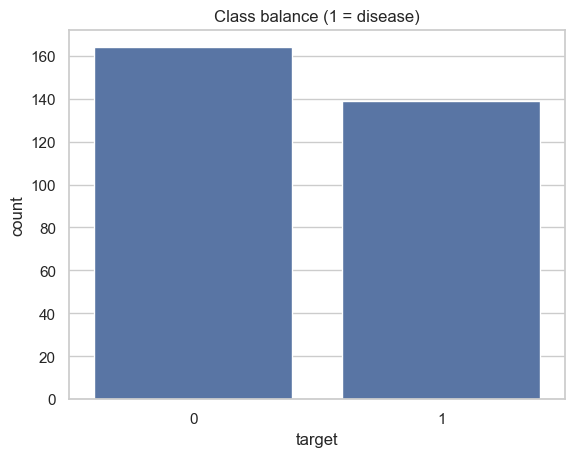

In [4]:
# سلول ۳: تعادل کلاس‌ها
print(df["target"].value_counts())
print(df["target"].value_counts(normalize=True).round(3))
sns.countplot(x="target", data=df)
plt.title("Class balance (1 = disease)")
plt.show()

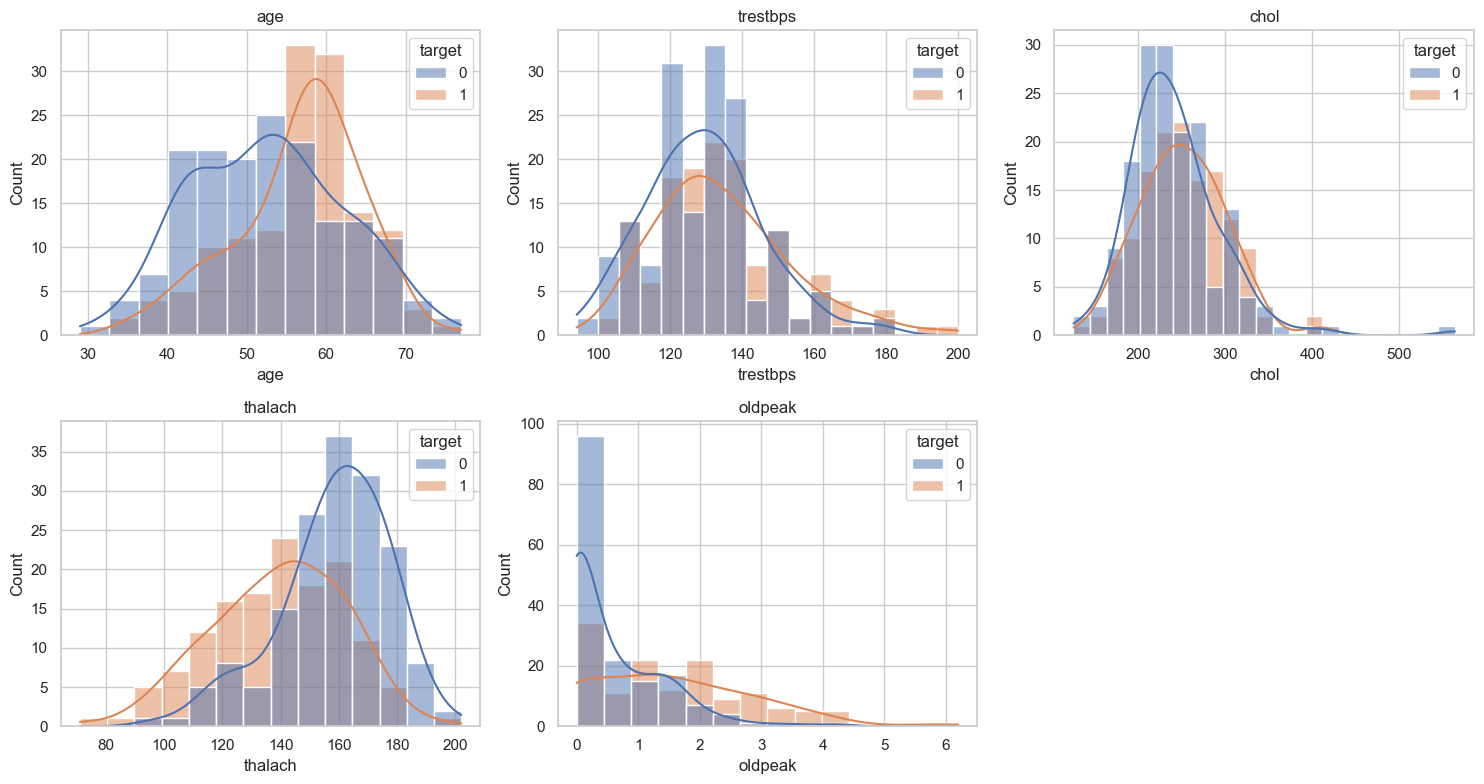

target,0,1
age,52.59,56.63
trestbps,129.25,134.57
chol,242.64,251.47
thalach,158.38,139.26
oldpeak,0.59,1.57


In [5]:
# سلول ۴: ویژگی‌های عددی به تفکیک target
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=col, hue="target", kde=True, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

df.groupby("target")[num_cols].mean().T.round(2)

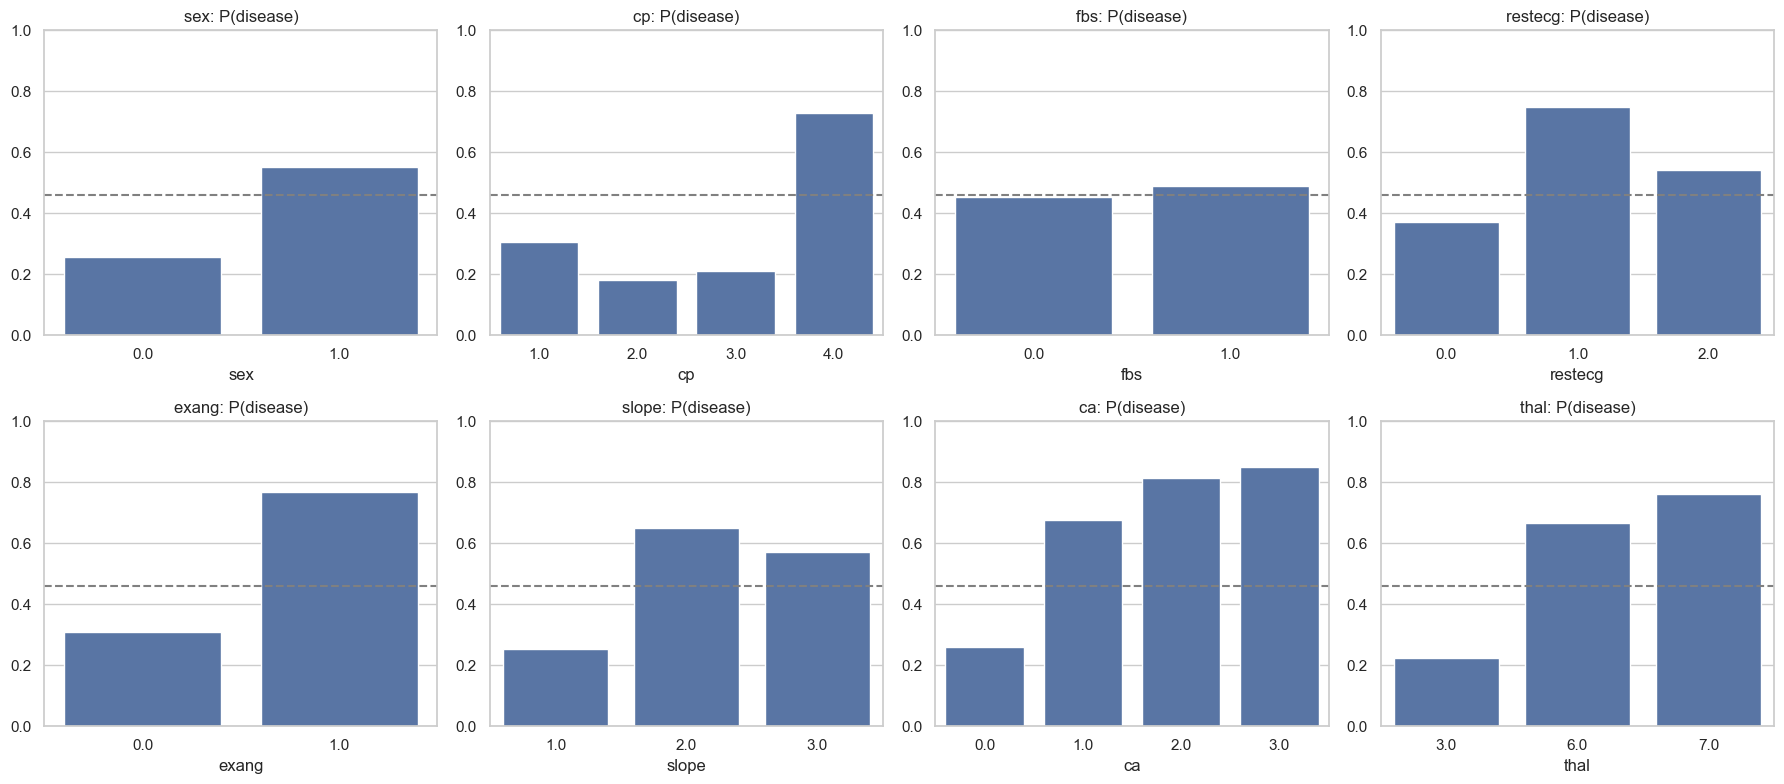

In [6]:
# سلول ۵: ویژگی‌های دسته‌ای
cat_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)["target"].mean()
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.axhline(df["target"].mean(), ls="--", c="gray")
    ax.set_title(f"{col}: P(disease)")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

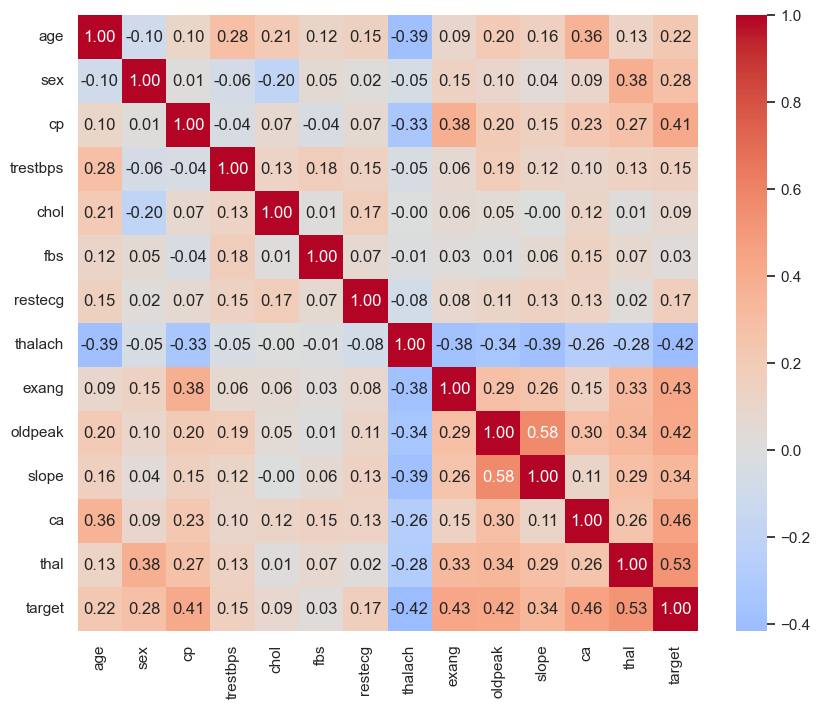

thalach    -0.417167
fbs         0.025264
chol        0.085164
trestbps    0.150825
restecg     0.169202
age         0.223120
sex         0.276816
slope       0.339213
cp          0.414446
oldpeak     0.424510
exang       0.431894
ca          0.460442
thal        0.525689
Name: target, dtype: float64

In [7]:
# سلول ۶: همبستگی
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

df.corr()["target"].drop("target").sort_values()

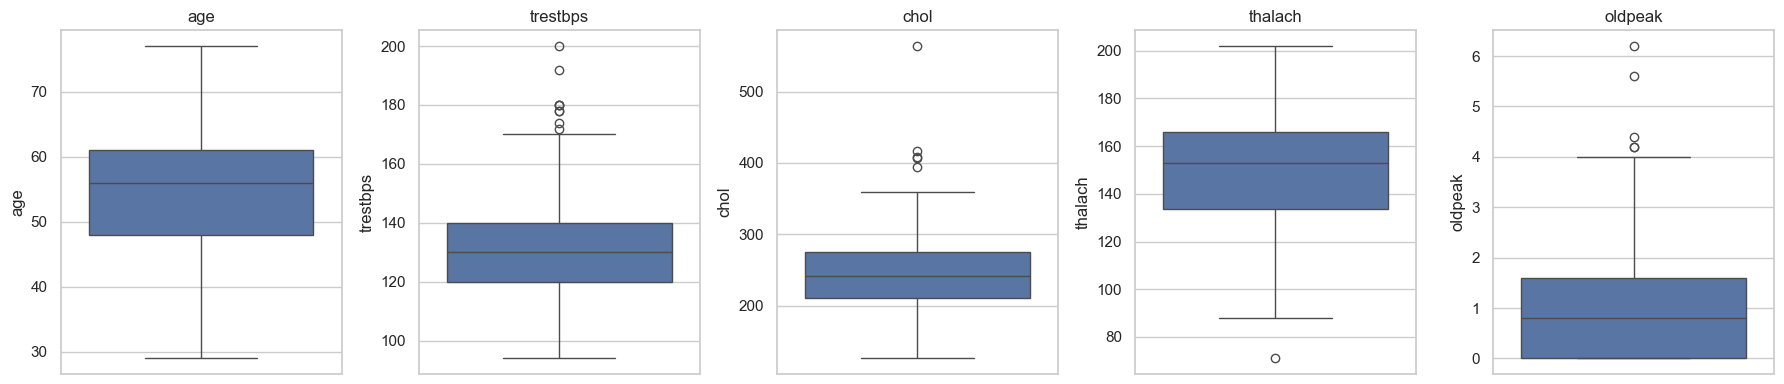

In [8]:
# سلول ۷: داده‌های پرت
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [9]:
limits = {"age": (18, 100), "trestbps": (80, 220), "chol": (100, 600),
          "thalach": (60, 220), "oldpeak": (0, 7)}

for col, (lo, hi) in limits.items():
    bad = ((df[col] < lo) | (df[col] > hi)).sum()
    print(f"{col:9s} min={df[col].min():6.1f} max={df[col].max():6.1f}  خارج از بازه: {bad}")

age       min=  29.0 max=  77.0  خارج از بازه: 0
trestbps  min=  94.0 max= 200.0  خارج از بازه: 0
chol      min= 126.0 max= 564.0  خارج از بازه: 0
thalach   min=  71.0 max= 202.0  خارج از بازه: 0
oldpeak   min=   0.0 max=   6.2  خارج از بازه: 0


In [10]:
from scipy import stats
for col in ["age", "trestbps", "chol", "thalach", "oldpeak"]:
    a = df.loc[df.target == 1, col]
    b = df.loc[df.target == 0, col]
    d = (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)
    p = stats.ttest_ind(a, b, equal_var=False).pvalue
    print(f"{col:9s} d={d:+.2f}  p={p:.4f}")

age       d=+0.46  p=0.0001
trestbps  d=+0.30  p=0.0094
chol      d=+0.17  p=0.1366
thalach   d=-0.91  p=0.0000
oldpeak   d=+0.92  p=0.0000
